Loaded EIS Data Shape: (14, 10)
      Re(Z)     Im(Z)        Xc  Frequency (Hz)
0  0.069988 -0.004840  0.004840    3.155748e+07
1  0.068360 -0.003978  0.003978    3.839897e+07
2  0.067082 -0.002720  0.002720    5.615042e+07
3  0.066565 -0.002094  0.002094    7.295141e+07
4  0.065644 -0.001834  0.001834    8.327643e+07

New CSV saved as: EIS_Bat12_with_Estimated_Frequency.csv


C:\Users\Hp\AppData\Local\Temp\ipykernel_17200\23019942.py:15: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  impedance_data = df.applymap(str_to_complex)


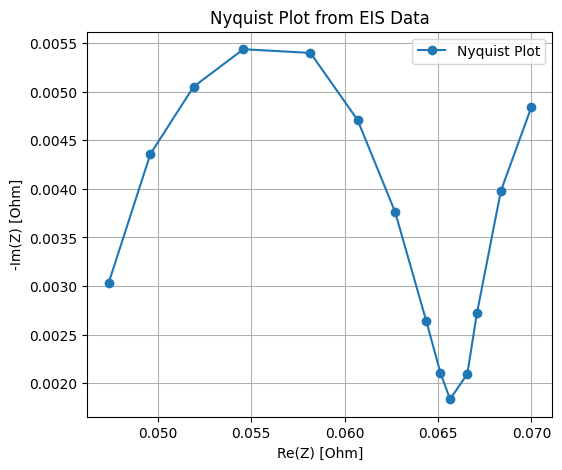

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load CSV without headers
file_path = 'EIS_Bat12.csv'
df = pd.read_csv(file_path, header=None)

# Function to convert string to complex
def str_to_complex(s):
    s = s.replace('i', 'j')  # Python uses 'j' for imaginary part
    return complex(s)

# Apply to entire dataframe
impedance_data = df.applymap(str_to_complex)
print("Loaded EIS Data Shape:", impedance_data.shape)

# Split real and imaginary parts into two separate columns
df_split = pd.DataFrame()
df_split['Re(Z)'] = impedance_data[1].apply(lambda z: z.real)
df_split['Im(Z)'] = impedance_data[1].apply(lambda z: z.imag)

# Calculate Capacitive Reactance Xc
df_split["Xc"] = abs(df_split["Im(Z)"])

# Assume Capacitance value (approximate from paper)
C = 1.042e-6  # Farads (1.042 uF)

# Calculate Frequency: f = 1 / (2 * pi * Xc * C)
df_split["Frequency (Hz)"] = 1 / (2 * np.pi * df_split["Xc"] * C)

# Show first few rows
print(df_split.head())

# Save to new CSV
output_file = "EIS_Bat12_with_Estimated_Frequency.csv"
df_split.to_csv(output_file, index=False)
print(f"\nNew CSV saved as: {output_file}")

# Optional: Nyquist Plot
plt.figure(figsize=(6,5))
plt.plot(df_split['Re(Z)'], -df_split['Im(Z)'], 'o-', label="Nyquist Plot")
plt.xlabel('Re(Z) [Ohm]')
plt.ylabel('-Im(Z) [Ohm]')
plt.title('Nyquist Plot from EIS Data')
plt.grid(True)
plt.legend()
plt.show()

C:\Users\Hp\AppData\Local\Temp\ipykernel_17200\1966564914.py:14: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  impedance_data = df.applymap(str_to_complex)


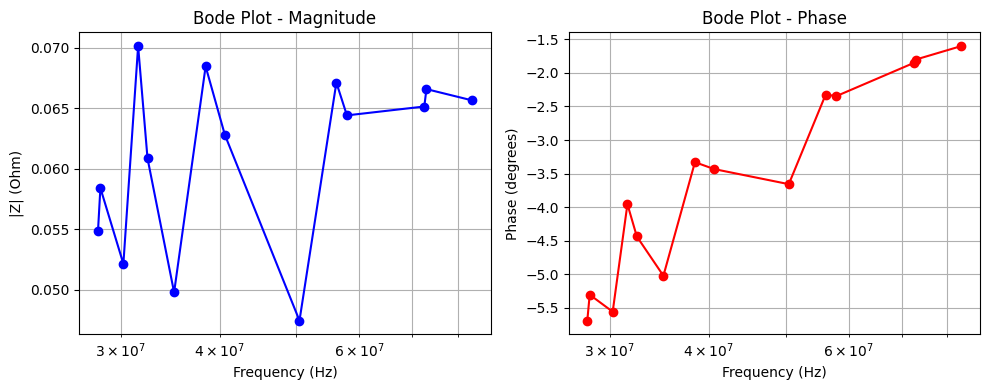


Updated CSV with Magnitude and Phase saved as: 'EIS_Bat12_with_Bode.csv'


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load CSV without headers
file_path = 'EIS_Bat12.csv'
df = pd.read_csv(file_path, header=None)

# Convert strings to complex numbers
def str_to_complex(s):
    s = s.replace('i', 'j')  # Python uses 'j' for imaginary numbers
    return complex(s)

impedance_data = df.applymap(str_to_complex)

# Split Real and Imag parts
df_split = pd.DataFrame()
df_split['Re(Z)'] = impedance_data[1].apply(lambda z: z.real)
df_split['Im(Z)'] = impedance_data[1].apply(lambda z: z.imag)

# Calculate Xc (reactance)
df_split["Xc"] = abs(df_split["Im(Z)"])

# Assume Capacitance from your paper
C = 1.042e-6  # Farads

# Calculate Frequency: f = 1 / (2 * pi * Xc * C)
df_split["Frequency (Hz)"] = 1 / (2 * np.pi * df_split["Xc"] * C)

# Calculate Magnitude |Z|
df_split["|Z|"] = np.sqrt(df_split["Re(Z)"]**2 + df_split["Im(Z)"]**2)

# Calculate Phase angle (degrees)
df_split["Phase (deg)"] = np.degrees(np.arctan2(df_split["Im(Z)"], df_split["Re(Z)"]))

# Sort by Frequency for plotting
df_split = df_split.sort_values(by="Frequency (Hz)")

# Bode Plot - Magnitude
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.semilogx(df_split["Frequency (Hz)"], df_split["|Z|"], marker='o', color='b')
plt.xlabel('Frequency (Hz)')
plt.ylabel('|Z| (Ohm)')
plt.title('Bode Plot - Magnitude')
plt.grid(True, which="both")

# Bode Plot - Phase
plt.subplot(1,2,2)
plt.semilogx(df_split["Frequency (Hz)"], df_split["Phase (deg)"], marker='o', color='r')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Phase (degrees)')
plt.title('Bode Plot - Phase')
plt.grid(True, which="both")

plt.tight_layout()
plt.show()

# Save updated dataframe
df_split.to_csv("EIS_Bat12_with_Bode.csv", index=False)
print("\nUpdated CSV with Magnitude and Phase saved as: 'EIS_Bat12_with_Bode.csv'")

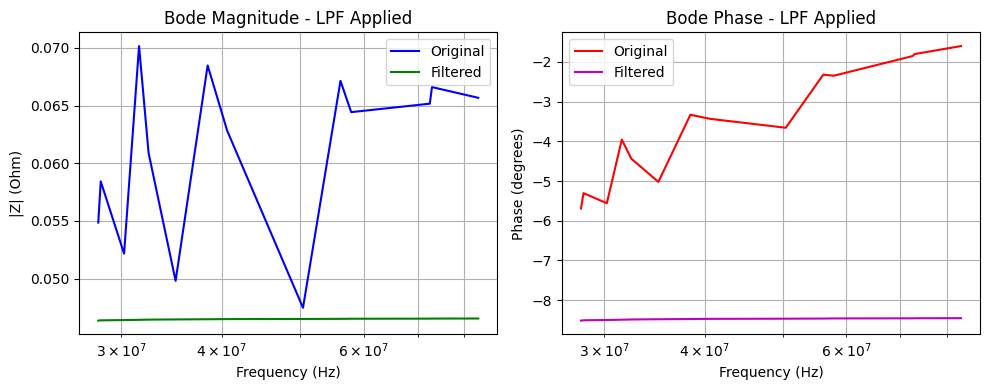

Filtered data saved as 'EIS_Bat12_with_Bode_Filtered.csv'


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

# Load your processed dataset (with magnitude & phase calculated)
df = pd.read_csv("EIS_Bat12_with_Bode.csv")

# Butterworth Low Pass Filter
def butter_lowpass_filter(data, cutoff, fs, order=3):
    nyq = 0.5 * fs  # Nyquist Frequency
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y

# Filter parameters
order = 3
fs = len(df)  # Sample rate (number of points)
cutoff = 0.1  # Cut-off frequency (as fraction of Nyquist)

# Apply LPF on |Z| (Magnitude) and Phase
df['|Z|_Filtered'] = butter_lowpass_filter(df['|Z|'], cutoff, fs, order)
df['Phase_Filtered'] = butter_lowpass_filter(df['Phase (deg)'], cutoff, fs, order)

# Plotting - Compare Original vs Filtered
plt.figure(figsize=(10,4))

# Magnitude
plt.subplot(1,2,1)
plt.semilogx(df["Frequency (Hz)"], df['|Z|'], 'b-', label='Original')
plt.semilogx(df["Frequency (Hz)"], df['|Z|_Filtered'], 'g-', label='Filtered')
plt.xlabel('Frequency (Hz)')
plt.ylabel('|Z| (Ohm)')
plt.title('Bode Magnitude - LPF Applied')
plt.legend()
plt.grid(True, which="both")

# Phase
plt.subplot(1,2,2)
plt.semilogx(df["Frequency (Hz)"], df['Phase (deg)'], 'r-', label='Original')
plt.semilogx(df["Frequency (Hz)"], df['Phase_Filtered'], 'm-', label='Filtered')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Phase (degrees)')
plt.title('Bode Phase - LPF Applied')
plt.legend()
plt.grid(True, which="both")

plt.tight_layout()
plt.show()

# Save filtered data
df.to_csv("EIS_Bat12_with_Bode_Filtered.csv", index=False)
print("Filtered data saved as 'EIS_Bat12_with_Bode_Filtered.csv'")

Loaded EIS Data Shape: (14, 10)

Filtered data saved as: 'EIS_Bat12_with_Bode_Filtered.csv'


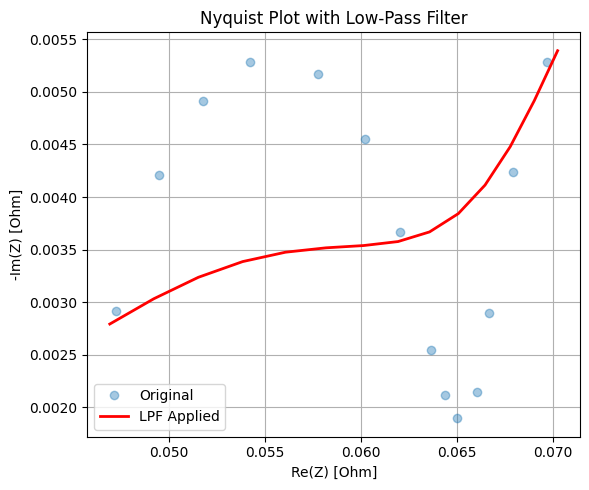

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

# ----------- Load CSV -----------
file_path = 'EIS_Bat12.csv'
df = pd.read_csv(file_path, header=None)

# ----------- Convert to Complex -----------
def str_to_complex(s):
    s = s.replace('i', 'j')
    return complex(s)

# Apply to all values (without applymap warning)
impedance_data = df.apply(lambda col: col.map(str_to_complex))
print("Loaded EIS Data Shape:", impedance_data.shape)

# ----------- Split Real & Imaginary -----------
df_split = pd.DataFrame()
df_split['Re(Z)'] = impedance_data[2].apply(lambda z: z.real)
df_split['Im(Z)'] = impedance_data[2].apply(lambda z: z.imag)
df_split['Xc'] = abs(df_split['Im(Z)'])

# ----------- Frequency Estimation -----------
C = 1.042e-6  # Capacitance in Farads
df_split["Frequency (Hz)"] = 1 / (2 * np.pi * df_split["Xc"] * C)

# ----------- Low Pass Filter Function -----------
def butter_lowpass_filter(data, cutoff, fs, order=2):
    if len(data) <= 13:
        print("Data too short for LPF. Returning original.")
        return data
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y

# ----------- Apply LPF -----------
cutoff_freq = 0.05
sampling_rate = 1.0
filter_order = 2

df_split['Re(Z)_filtered'] = butter_lowpass_filter(df_split['Re(Z)'], cutoff_freq, sampling_rate, filter_order)
df_split['Im(Z)_filtered'] = butter_lowpass_filter(df_split['Im(Z)'], cutoff_freq, sampling_rate, filter_order)

# ----------- Save Filtered Data -----------
output_file = "EIS_Bat12_with_Bode_Filtered.csv"
df_split.to_csv(output_file, index=False)
print(f"\nFiltered data saved as: '{output_file}'")

# ----------- Plot Nyquist (Original + Filtered) -----------
plt.figure(figsize=(6,5))
plt.plot(df_split['Re(Z)'], -df_split['Im(Z)'], 'o', alpha=0.4, label="Original")
plt.plot(df_split['Re(Z)_filtered'], -df_split['Im(Z)_filtered'], 'r-', linewidth=2, label="LPF Applied")
plt.xlabel('Re(Z) [Ohm]')
plt.ylabel('-Im(Z) [Ohm]')
plt.title('Nyquist Plot with Low-Pass Filter')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()